In [1]:
# ==========================================
# FUTURE 60-DAY BRENT PRICE FORECAST
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ==========================================
# 1. PROJECT PATHS
# ==========================================

ROOT = Path.cwd().resolve().parent

RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. LOAD FORECAST DATA
# ==========================================

mlp = pd.read_csv(
    RESULTS / "mlp_forecast60.csv"
)

arimax = pd.read_csv(
    RESULTS / "arimax_forecast60.csv"
)

print("MLP columns:", mlp.columns.tolist())
print("ARIMAX columns:", arimax.columns.tolist())

MLP columns: ['Horizon', 'MLP']
ARIMAX columns: ['Horizon', 'ARIMAX']


In [2]:
# ==========================================
# 3. PREPARE MLP AND RANDOM WALK
# ==========================================

mlp.columns = mlp.columns.str.strip()

mlp = mlp.sort_values("Horizon").reset_index(drop=True)

# Random Walk: last observed Brent price
if "Random_Walk" not in mlp.columns:

    historical = pd.read_csv(
        ROOT / "data" / "data.csv"
    )

    last_price = historical["brent_Price"].iloc[-1]

    mlp["Random_Walk"] = last_price

mlp = mlp[
    ["Horizon", "MLP", "Random_Walk"]
].copy()

# ==========================================
# 4. PREPARE ARIMAX
# ==========================================

# Accept common ARIMAX column names
if "ARIMAX" not in arimax.columns:

    for candidate in [
        "Forecast",
        "Predicted",
        "Predicted_Price"
    ]:
        if candidate in arimax.columns:
            arimax = arimax.rename(
                columns={candidate: "ARIMAX"}
            )
            break

if "ARIMAX" not in arimax.columns:
    raise ValueError(
        "ARIMAX CSV must contain an ARIMAX forecast column."
    )

# Match forecasts by horizon
if "Horizon" not in arimax.columns:

    if len(arimax) != 60:
        raise ValueError(
            "ARIMAX CSV needs 60 rows or a Horizon column."
        )

    arimax["Horizon"] = np.arange(1, 61)

arimax["Horizon"] = pd.to_numeric(
    arimax["Horizon"]
)

# ==========================================
# 5. MERGE THREE FORECASTS
# ==========================================

forecast = pd.merge(
    mlp,
    arimax[["Horizon", "ARIMAX"]],
    on="Horizon",
    how="inner",
    validate="one_to_one"
)

forecast = forecast.sort_values(
    "Horizon"
).reset_index(drop=True)

if (
    len(forecast) != 60
    or forecast["Horizon"].tolist() != list(range(1, 61))
):
    raise ValueError(
        "Forecasts must contain all horizons from 1 to 60."
    )

for col in ["MLP", "ARIMAX", "Random_Walk"]:
    forecast[col] = pd.to_numeric(
        forecast[col],
        errors="raise"
    )

if not np.isfinite(
    forecast[["MLP", "ARIMAX", "Random_Walk"]]
    .to_numpy(dtype=float)
).all():
    raise ValueError("Forecast contains missing or invalid values.")

# ==========================================
# 6. COLORS
# ==========================================

colors = {
    "ARIMAX": "#E64B35",
    "Random Walk": "#8491B4",
    "MLP": "#4DBBD5"
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#555555",
    "text.color": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#444444",
    "ytick.color": "#444444"
})

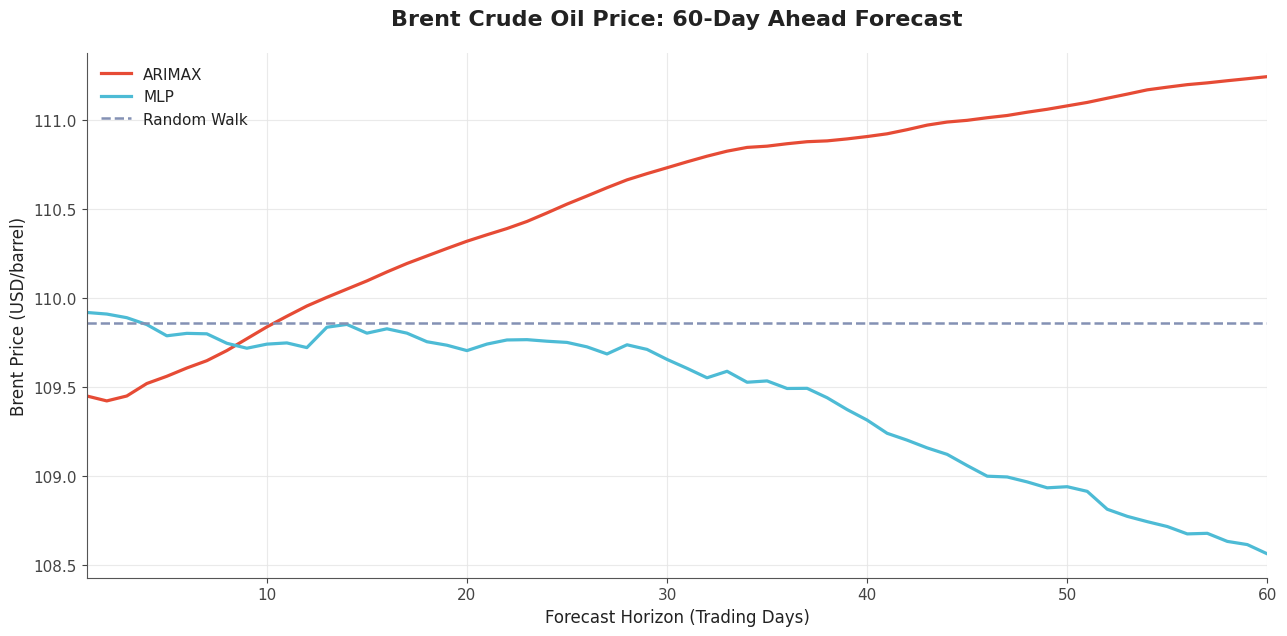


60-DAY FORECAST COMPARISON

 Horizon  Horizon   ARIMAX      MLP  Random_Walk
       1        1 109.4489 109.9186       109.86
       2        2 109.4211 109.9097       109.86
       3        3 109.4488 109.8892       109.86
       4        4 109.5189 109.8504       109.86
       5        5 109.5597 109.7874       109.86
       6        6 109.6062 109.8011       109.86
       7        7 109.6474 109.7985       109.86
       8        8 109.7043 109.7453       109.86
       9        9 109.7708 109.7175       109.86
      10       10 109.8374 109.7404       109.86
      11       11 109.8973 109.7473       109.86
      12       12 109.9550 109.7209       109.86
      13       13 110.0037 109.8356       109.86
      14       14 110.0500 109.8514       109.86
      15       15 110.0961 109.8022       109.86
      16       16 110.1466 109.8267       109.86
      17       17 110.1940 109.8023       109.86
      18       18 110.2364 109.7540       109.86
      19       19 110.2785 109.7344     

In [3]:
# ==========================================
# 7. PLOT FUTURE FORECASTS
# ==========================================

fig, ax = plt.subplots(
    figsize=(13, 6.5)
)

ax.plot(
    forecast["Horizon"],
    forecast["ARIMAX"],
    color=colors["ARIMAX"],
    linewidth=2.3,
    label="ARIMAX"
)

ax.plot(
    forecast["Horizon"],
    forecast["MLP"],
    color=colors["MLP"],
    linewidth=2.3,
    label="MLP"
)

ax.plot(
    forecast["Horizon"],
    forecast["Random_Walk"],
    color=colors["Random Walk"],
    linewidth=1.8,
    linestyle="--",
    label="Random Walk"
)

# ==========================================
# 8. FORMATTING
# ==========================================

ax.set_title(
    "Brent Crude Oil Price: 60-Day Ahead Forecast",
    pad=20
)

ax.set_xlabel("Forecast Horizon (Trading Days)")
ax.set_ylabel("Brent Price (USD/barrel)")

ax.set_xlim(1, 60)

ax.grid(
    axis="both",
    color="#E5E5E5",
    linewidth=0.8,
    alpha=0.8
)

ax.legend(
    loc="best",
    frameon=False,
    fontsize=11
)

ax.margins(x=0.02)

fig.tight_layout()

# ==========================================
# 9. SAVE PNG
# ==========================================

output_path = (
    FIGURES / "future_60day_model_comparison.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 10. DISPLAY FORECAST TABLE
# ==========================================

print("\n60-DAY FORECAST COMPARISON\n")

print(
    forecast[
        ["Horizon", "Horizon", "ARIMAX", "MLP", "Random_Walk"]
    ].round(4).to_string(index=False)
)

print("\nFigure saved to:")
print(output_path)